In [2]:
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import rasterio
import xarray as xr
from matplotlib.lines import Line2D

In [3]:
from paths import path_to_tiles_metadata_EAGLE_2016
from paths import path_to_tiles_tensor_EAGLE_2016 

from paths import path_to_tiles_metadata_IceBridge_HiCARS1
from paths import path_to_tiles_tensor_IceBridge_HiCARS1

from paths import path_to_tiles_metadata_IceBridge_HiCARS2
from paths import path_to_tiles_tensor_IceBridge_HiCARS2

from paths import path_to_tiles_metadata, path_to_tiles_tensor

# Import all tensors

In [4]:
tensor_EAGLE_2016 = torch.load(path_to_tiles_tensor_EAGLE_2016)
tensor_IceBridge_HiCARS1 = torch.load(path_to_tiles_tensor_IceBridge_HiCARS1)
tensor_IceBridge_HiCARS2 = torch.load(path_to_tiles_tensor_IceBridge_HiCARS2)

In [5]:
tiles = torch.cat([
    tensor_EAGLE_2016,
    tensor_IceBridge_HiCARS1,
    tensor_IceBridge_HiCARS2], dim = 0)

print(f"Combined tensor shape: {tiles.shape}")

Combined tensor shape: torch.Size([10815, 1, 336, 336])


# Import all metadata

In [6]:
meta_EAGLE_2016 = pd.read_csv(path_to_tiles_metadata_EAGLE_2016)
meta_IceBridge_HiCARS1 = pd.read_csv(path_to_tiles_metadata_IceBridge_HiCARS1)
meta_IceBridge_HiCARS2 = pd.read_csv(path_to_tiles_metadata_IceBridge_HiCARS2)

In [7]:
meta_EAGLE_2016

,granule_id,flight,x_center_idx,y_center_idx,tile_id,X,Y,LON,LAT,bed_elevation,surface_elevation,ice_thickness,partial_bed_reflect,srf_reflect,tile_along_track_span_m,tile_vertical_span_m,bed_std_m,peak_bed_echo_db
0,ER2HI1B_2017023_ICP8_JKB2r_F07T02a_000,ICP8/F07,168,1054,ER2HI1B_2017023_ICP8_JKB2r_F07T02a_000_0168,2.233971e+06,-1.003400e+06,114.187485,-67.733750,-364.43,774.85,1139.28,-51.14,-13.08,6386.525126,-567.550895,45.556204,196.545
1,ER2HI1B_2017023_ICP8_JKB2r_F07T03a_000,ICP8/F07,840,1022,ER2HI1B_2017023_ICP8_JKB2r_F07T03a_000_0840,2.300701e+06,-8.993874e+05,111.351460,-67.544975,-234.70,960.39,1195.09,NaN,-13.48,5963.723460,-567.550741,41.048903,186.433
2,ER2HI1B_2017023_ICP8_JKB2r_F07T05a_000,ICP8/F07,168,1111,ER2HI1B_2017023_ICP8_JKB2r_F07T05a_000_0168,2.311783e+06,-9.074552e+05,111.431730,-67.427400,-461.39,803.03,1264.42,-61.86,-32.32,7788.083221,-567.550741,134.157683,178.590
3,ER2HI1B_2017023_ICP8_JKB2r_F07T05a_000,ICP8/F07,504,1021,ER2HI1B_2017023_ICP8_JKB2r_F07T05a_000_0504,2.309200e+06,-9.009693e+05,111.313995,-67.469670,-309.08,815.82,1124.90,-48.56,-13.35,6817.404817,-567.550972,95.571549,199.023
4,ER2HI1B_2017023_ICP8_JKB2r_F07T05a_000,ICP8/F07,840,1038,ER2HI1B_2017023_ICP8_JKB2r_F07T05a_000_0840,2.303299e+06,-9.004596e+05,111.352684,-67.520050,-305.99,893.33,1199.32,NaN,-29.01,5881.549013,-567.550972,65.878738,183.386
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
631,ER2HI1B_2017034_DEN_JKB2r_Y50a_000,ICP8/F14,1512,1274,ER2HI1B_2017034_DEN_JKB2r_Y50a_000_1512,2.522422e+06,-4.521052e+05,100.161400,-66.726880,-1013.32,613.75,1627.07,NaN,-9.85,7327.740001,-567.550741,111.406558,169.304
632,ER2HI1B_2017034_DEN_JKB2r_Y50a_000,ICP8/F14,2520,1000,ER2HI1B_2017034_DEN_JKB2r_Y50a_000_2520,2.514960e+06,-4.314182e+05,99.733760,-66.823494,-575.99,535.73,1111.72,NaN,-8.17,7712.768837,-567.550895,51.215338,181.451
633,ER2HI1B_2017034_DEN_JKB2r_Y50a_000,ICP8/F14,3528,523,ER2HI1B_2017034_DEN_JKB2r_Y50a_000_3528,2.507020e+06,-4.098388e+05,99.284240,-66.924330,229.01,592.25,363.24,-46.89,-6.96,7165.212069,-567.550665,49.764983,205.953
634,ER2HI1B_2017034_DEN_JKB2r_Y50a_001,ICP8/F14,168,701,ER2HI1B_2017034_DEN_JKB2r_Y50a_001_0168,2.502582e+06,-3.979182e+05,99.034550,-66.979920,240.07,858.46,618.38,NaN,-11.60,6643.045015,-567.550665,34.648211,187.294


In [8]:
meta_list = [meta_EAGLE_2016, meta_IceBridge_HiCARS1, meta_IceBridge_HiCARS2]

metas = pd.concat(meta_list, ignore_index = True)

In [9]:
metas

,granule_id,flight,x_center_idx,y_center_idx,tile_id,X,Y,LON,LAT,bed_elevation,surface_elevation,ice_thickness,partial_bed_reflect,srf_reflect,tile_along_track_span_m,tile_vertical_span_m,bed_std_m,peak_bed_echo_db
0,ER2HI1B_2017023_ICP8_JKB2r_F07T02a_000,ICP8/F07,168,1054,ER2HI1B_2017023_ICP8_JKB2r_F07T02a_000_0168,2.233971e+06,-1.003400e+06,114.187485,-67.733750,-364.43,774.85,1139.28,-51.14,-13.08,6386.525126,-567.550895,45.556204,196.545
1,ER2HI1B_2017023_ICP8_JKB2r_F07T03a_000,ICP8/F07,840,1022,ER2HI1B_2017023_ICP8_JKB2r_F07T03a_000_0840,2.300701e+06,-8.993874e+05,111.351460,-67.544975,-234.70,960.39,1195.09,NaN,-13.48,5963.723460,-567.550741,41.048903,186.433
2,ER2HI1B_2017023_ICP8_JKB2r_F07T05a_000,ICP8/F07,168,1111,ER2HI1B_2017023_ICP8_JKB2r_F07T05a_000_0168,2.311783e+06,-9.074552e+05,111.431730,-67.427400,-461.39,803.03,1264.42,-61.86,-32.32,7788.083221,-567.550741,134.157683,178.590
3,ER2HI1B_2017023_ICP8_JKB2r_F07T05a_000,ICP8/F07,504,1021,ER2HI1B_2017023_ICP8_JKB2r_F07T05a_000_0504,2.309200e+06,-9.009693e+05,111.313995,-67.469670,-309.08,815.82,1124.90,-48.56,-13.35,6817.404817,-567.550972,95.571549,199.023
4,ER2HI1B_2017023_ICP8_JKB2r_F07T05a_000,ICP8/F07,840,1038,ER2HI1B_2017023_ICP8_JKB2r_F07T05a_000_0840,2.303299e+06,-9.004596e+05,111.352684,-67.520050,-305.99,893.33,1199.32,NaN,-29.01,5881.549013,-567.550972,65.878738,183.386
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10810,IR2HI1B_2012346_WSB_JKB2h_R40b_010,ICP5/F18,504,1633,IR2HI1B_2012346_WSB_JKB2h_R40b_010_0504,5.253390e+05,-1.209101e+06,156.515850,-77.910126,383.18,2149.82,1766.64,-70.47,-13.95,7733.431278,-567.550741,122.428389,167.868
10811,IR2HI1B_2012346_WSB_JKB2h_R40b_010,ICP5/F18,840,1178,IR2HI1B_2012346_WSB_JKB2h_R40b_010_0840,5.180543e+05,-1.211759e+06,156.852360,-77.914154,1144.23,2133.79,989.56,-54.06,-12.14,7780.654742,-567.550741,234.919537,185.486
10812,IR2HI1B_2012346_WSB_JKB2h_R40b_010,ICP5/F18,1176,1643,IR2HI1B_2012346_WSB_JKB2h_R40b_010_1176,5.107318e+05,-1.214441e+06,157.191020,-77.917700,362.83,2150.23,1787.40,NaN,-14.13,7810.907713,-567.550741,242.606880,149.676
10813,IR2HI1B_2012346_WSB_JKB2h_R40b_010,ICP5/F18,1512,1134,IR2HI1B_2012346_WSB_JKB2h_R40b_010_1512,5.033827e+05,-1.217118e+06,157.530870,-77.920960,1257.48,2227.37,969.89,-37.47,-14.09,7836.124150,-567.550895,264.692946,198.221


In [10]:
flight_idx, flight_names = pd.factorize(metas['flight'].str[:4])
flight_names.value_counts()

ICP8    1
ICP1    1
ICP2    1
ICP3    1
ICP4    1
ICP5    1
Name: count, dtype: int64

No ICECAP7 currently (has more issues.) On ICP8 flights F01 to F06, the antenna beam pattern had a nadir-directed null due to a reversed balun.

In [28]:
year_idx, year_names = pd.factorize(metas['granule_id'].str[8:12])
year_names.value_counts()

2017    1
2009    1
2010    1
2011    1
2012    1
Name: count, dtype: int64

In [11]:
metas["campaign"] = metas['flight'].str[:4]

In [12]:
survey_idx, survey_names = pd.factorize(metas["granule_id"].str[:5])
survey_names.value_counts()

ER2HI    1
IR1HI    1
IR2HI    1
Name: count, dtype: int64

In [13]:
metas["survey"] = metas["granule_id"].str[:5]

# Normalise

In [14]:
batch_size = 50
q = torch.tensor([0.05, 0.95])

low_quantile_per_tile = []
high_quantile_per_tile = []

for i in range(0, tiles.shape[0], batch_size):
    batch = tiles[i:i + batch_size]                   
    flat = batch.reshape(batch.shape[0], batch.shape[1], -1).float()
    qs = torch.quantile(flat, q, dim = -1)         
    low_quantile_per_tile.append(qs[0])              
    high_quantile_per_tile.append(qs[1])

low_quantile_per_tile = torch.cat(low_quantile_per_tile)
high_quantile_per_tile = torch.cat(high_quantile_per_tile)

In [15]:
lower_absolute = torch.min(low_quantile_per_tile)
upper_absolute = torch.max(high_quantile_per_tile)

print(lower_absolute.item())
print(upper_absolute.item())

90.87999725341797
200.59225463867188


# Export combined files

In [15]:
torch.save(tiles, path_to_tiles_tensor)
metas.to_csv(path_to_tiles_metadata, index = False)

# Visualise EAGLE extent

In [18]:
from paths import path_to_modis_moa_750

with rasterio.open(path_to_modis_moa_750) as src:
    image = src.read(1)            
    t = src.transform            
    nrows, ncols = src.height, src.width
    nodata = src.nodata
    print(src.crs, src.res, image.dtype, image.shape)

# Pixel-CENTER coordinates, derived from the file itself.
# (t.c, t.f) is the upper-left CORNER, so add half a pixel.
x = t.c + (np.arange(ncols) + 0.5) * t.a        # increasing
y = t.f + (np.arange(nrows) + 0.5) * t.e        # decreasing (top -> bottom)

# Sanity check vs. your stated upper-left pixel centre (-3174450, 2406325)
print(x[0], y[0])

da = xr.DataArray(
    image,
    dims = ("y", "x"),
    coords = {"y": y, "x": x},
    name = "moa",
    attrs = {"long_name": "MODIS Mosaic of Antarctica 750 m",
           "grid_mapping": "polar_stereographic"},
)

ds = da.to_dataset()
ds["x"].attrs = {"standard_name": "projection_x_coordinate",
                 "long_name": "x coordinate of projection", "units": "m", "axis": "X"}
ds["y"].attrs = {"standard_name": "projection_y_coordinate",
                 "long_name": "y coordinate of projection", "units": "m", "axis": "Y"}

ds.to_netcdf("/Users/kim.bente/DATA/MODIS/moa750_2014_hp1_v01.nc")

PROJCS["unnamed",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257024882273,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Polar_Stereographic"],PARAMETER["latitude_of_origin",-71],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1],AXIS["Easting",NORTH],AXIS["Northing",NORTH]] (750.0, 750.0) uint16 (6964, 8056)
-3174075.0 2405950.0


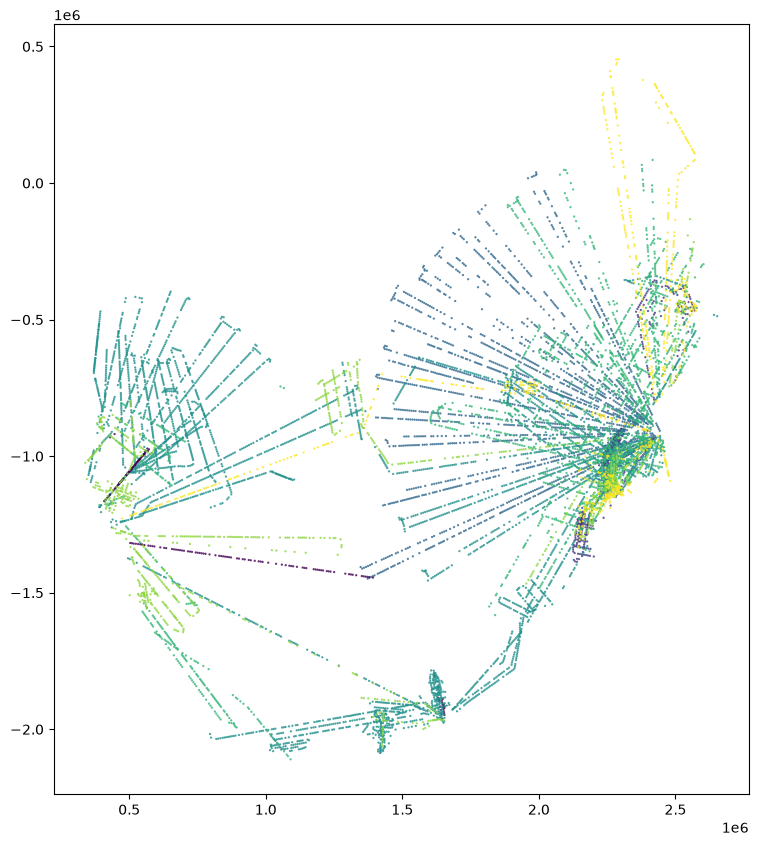

In [ ]:
plt.figure(figsize = (10, 10))
plt.scatter(metas['X'], metas['Y'], s = 0.6, c = flight_idx, alpha = 0.8, cmap = 'Reds')
plt.gca().set_aspect('equal', adjustable = 'box')
plt.show()

/var/folders/pv/_mchxpdj3tz_s_9735cr69pr0000gp/T/ipykernel_35999/584821446.py:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


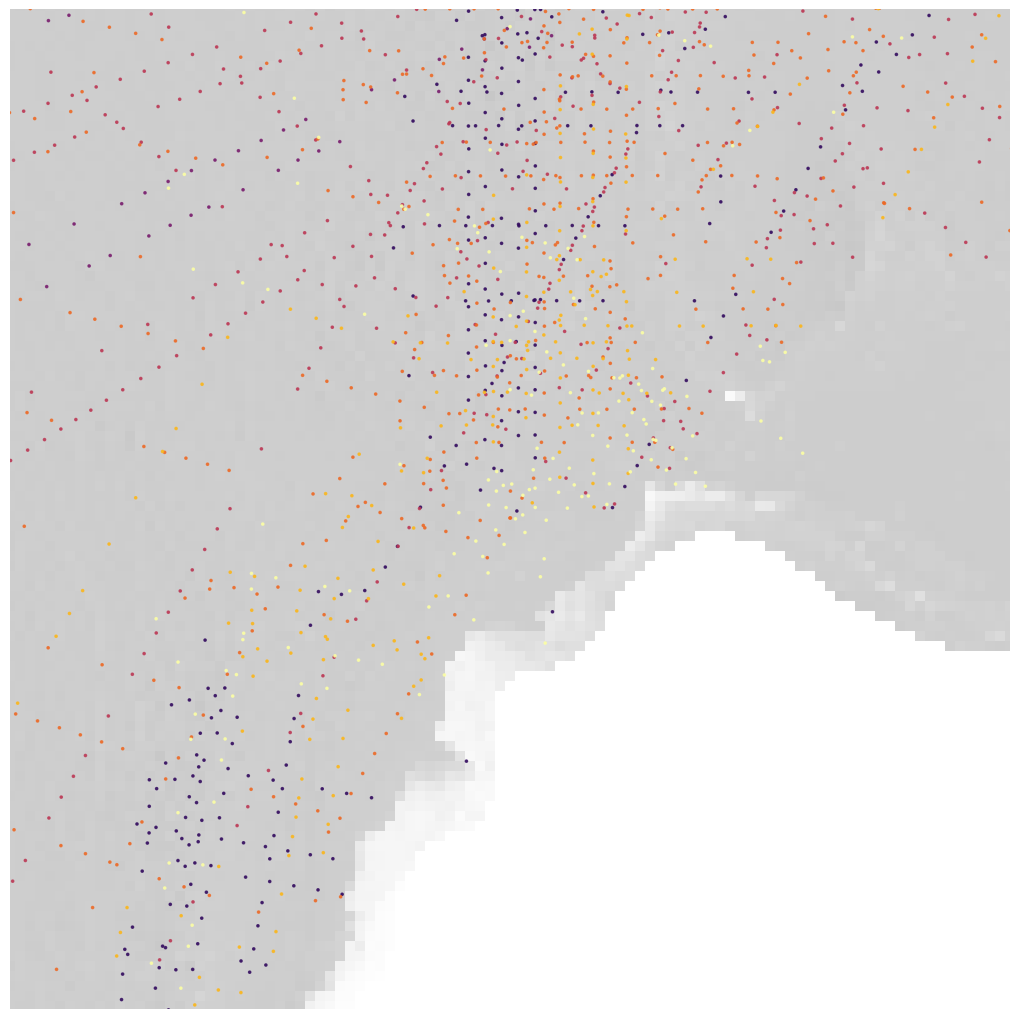

In [32]:
moa = xr.open_dataset("/Users/kim.bente/DATA/MODIS/moa750_2014_hp1_v01.nc")["moa"][::4, ::4]
moa = moa.where(moa != 0)

# Define lims
xlim = (2.1e6, 2.4e6)
ylim = (-1.3e6, -1.0e6)
aspect = (ylim[1] - ylim[0]) / (xlim[1] - xlim[0])

fig = plt.figure(figsize = (10, 10 * aspect))
ax = fig.add_axes([0, 0, 1, 1])
ax.set_axis_off()
ax.pcolormesh(moa.x, moa.y, moa, cmap = "gray_r", rasterized = True, vmin = 500, vmax = 80000)
ax.scatter(metas['X'], metas['Y'], s = 2.6, c = flight_idx, alpha = 0.8, cmap = 'inferno')
ax.set_ylim(ylim)
ax.set_xlim(xlim)
ax.set_aspect('equal', adjustable = 'box')

fig.savefig("figures/radar_data_extent_zoom.png", dpi = 300, pad_inches = 0, transparent = False)
fig.show()

/var/folders/pv/_mchxpdj3tz_s_9735cr69pr0000gp/T/ipykernel_35999/3778501145.py:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


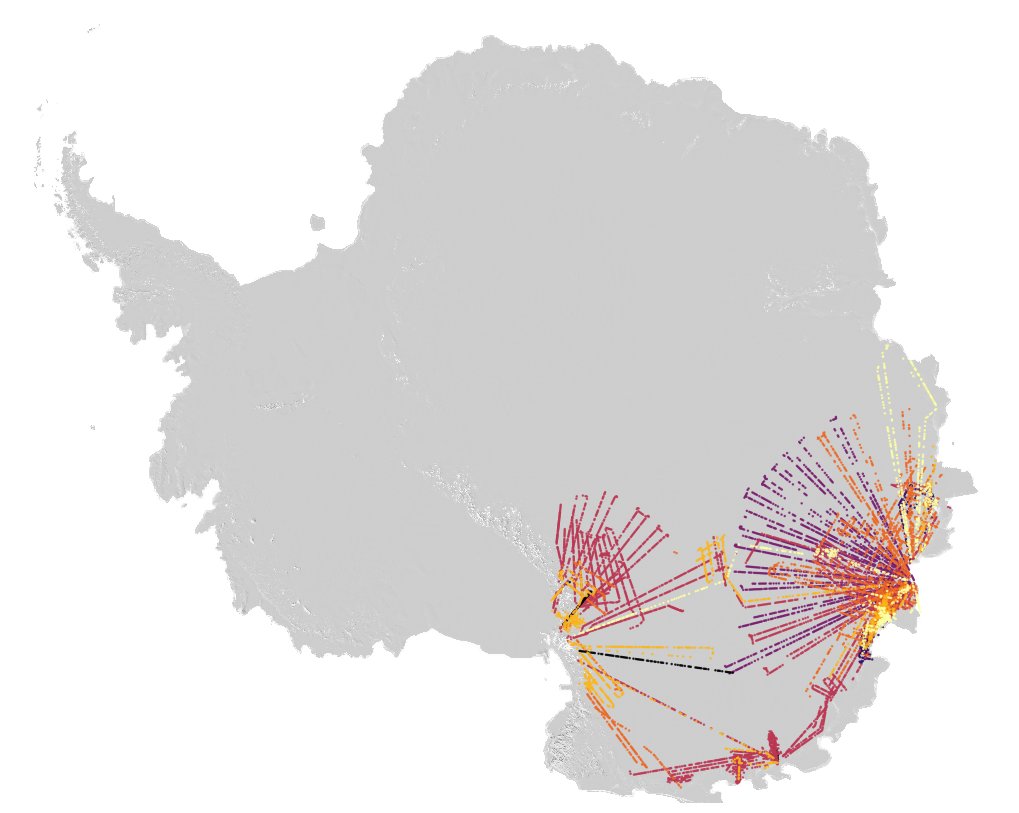

In [33]:
moa = xr.open_dataset("/Users/kim.bente/DATA/MODIS/moa750_2014_hp1_v01.nc")["moa"][::4, ::4]
moa = moa.where(moa != 0)

# Define lims
xlim = (-2.8e6, 3.0e6)
ylim = (-2.2e6, 2.4e6)
aspect = (ylim[1] - ylim[0]) / (xlim[1] - xlim[0])

fig = plt.figure(figsize = (10, 10 * aspect))
ax = fig.add_axes([0, 0, 1, 1])
ax.set_axis_off()
ax.pcolormesh(moa.x, moa.y, moa, cmap = "gray_r", rasterized = True, vmin = 500, vmax = 80000)
ax.scatter(metas['X'], metas['Y'], s = 0.6, c = flight_idx, alpha = 0.8, cmap = 'inferno')
ax.set_ylim(ylim)
ax.set_xlim(xlim)
ax.set_aspect('equal', adjustable = 'box')

fig.savefig("figures/radar_data_extent.png", dpi = 300, pad_inches = 0, transparent = False)
fig.show()

# Label Datasets

/var/folders/pv/_mchxpdj3tz_s_9735cr69pr0000gp/T/ipykernel_35999/438984114.py:24: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


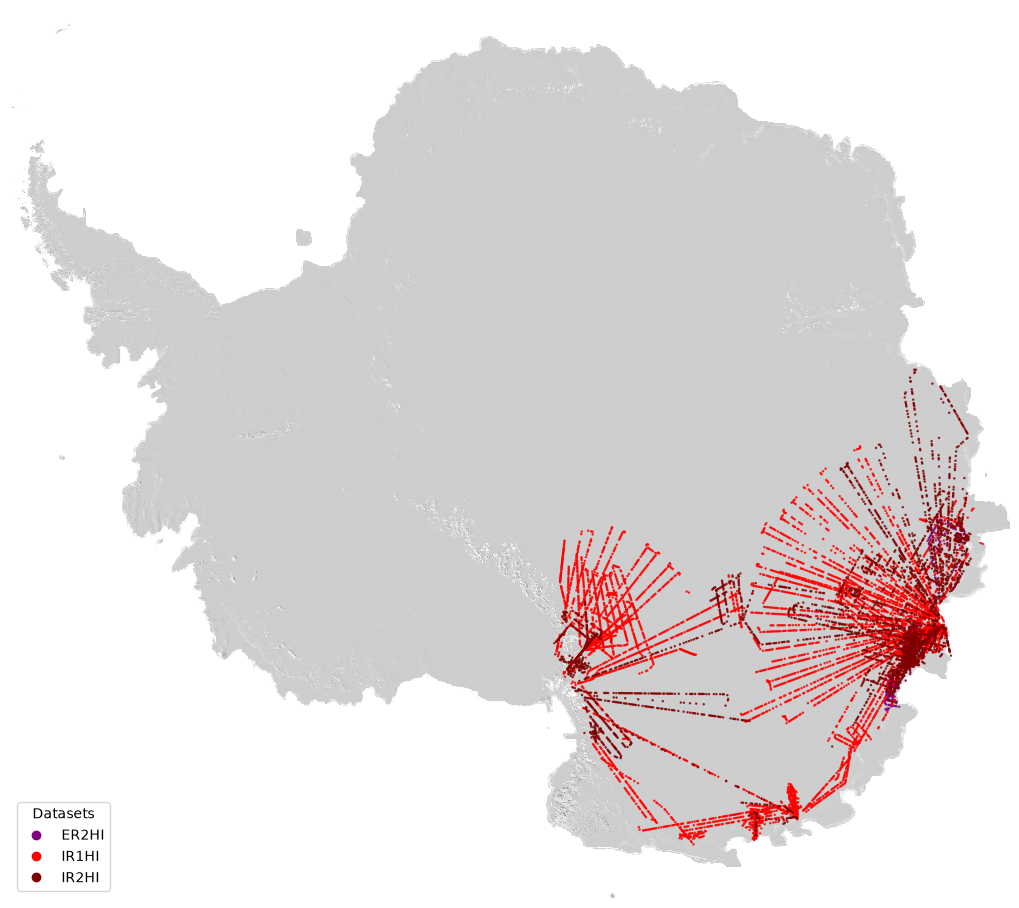

In [45]:
moa = xr.open_dataset("/Users/kim.bente/DATA/MODIS/moa750_2014_hp1_v01.nc")["moa"][::4, ::4]
moa = moa.where(moa != 0)

colors = ["purple", "red", "maroon"]

# Define lims
xlim = (-2.6e6, 2.8e6)
ylim = (-2.4e6, 2.4e6)
aspect = (ylim[1] - ylim[0]) / (xlim[1] - xlim[0])

fig = plt.figure(figsize = (10, 10 * aspect))
ax = fig.add_axes([0, 0, 1, 1])
ax.set_axis_off()
ax.pcolormesh(moa.x, moa.y, moa, cmap = "gray_r", rasterized = True, vmin = 500, vmax = 80000)
sc = ax.scatter(metas['X'], metas['Y'], s = 0.6, c = [colors[i] for i in survey_idx], alpha = 0.8)

ax.set_ylim(ylim)
ax.set_xlim(xlim)
ax.set_aspect('equal', adjustable = 'box')
handles = [Line2D([], [], marker='o', linestyle='', color=c, markersize=6) for c in colors]
ax.legend(handles, survey_names, title = "Datasets", loc = "lower left", frameon = True)

fig.savefig("figures/radar_data_extent_by_datasets.png", dpi = 300, pad_inches = 0, transparent = False)
fig.show()

/var/folders/pv/_mchxpdj3tz_s_9735cr69pr0000gp/T/ipykernel_85222/1180315934.py:24: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


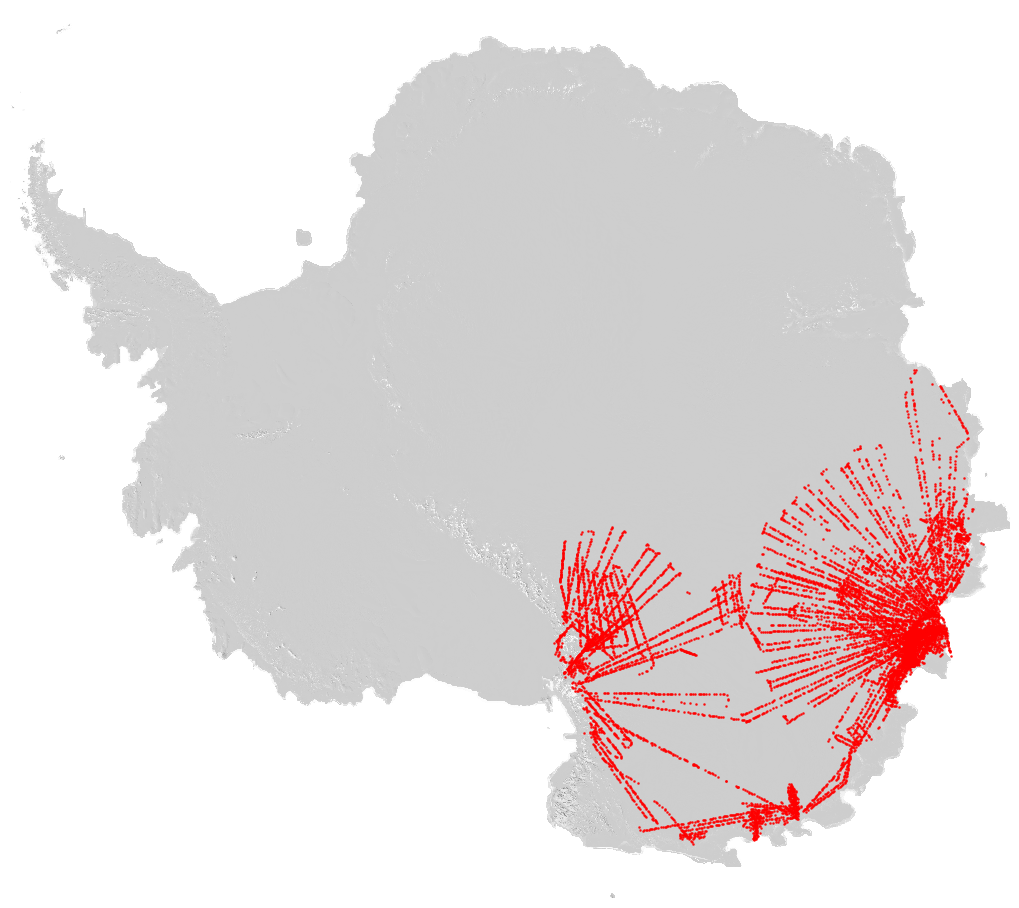

In [29]:
moa = xr.open_dataset("/Users/kim.bente/DATA/MODIS/moa750_2014_hp1_v01.nc")["moa"][::4, ::4]
moa = moa.where(moa != 0)

colors = ["purple", "red", "maroon"]

# Define lims
xlim = (-2.6e6, 2.8e6)
ylim = (-2.4e6, 2.4e6)
aspect = (ylim[1] - ylim[0]) / (xlim[1] - xlim[0])

fig = plt.figure(figsize = (10, 10 * aspect))
ax = fig.add_axes([0, 0, 1, 1])
ax.set_axis_off()
ax.pcolormesh(moa.x, moa.y, moa, cmap = "gray_r", rasterized = True, vmin = 500, vmax = 80000)
sc = ax.scatter(metas['X'], metas['Y'], s = 0.8, c = "red", alpha = 0.8)

ax.set_ylim(ylim)
ax.set_xlim(xlim)
ax.set_aspect('equal', adjustable = 'box')
# handles = [Line2D([], [], marker='o', linestyle='', color=c, markersize=6) for c in colors]
# ax.legend(handles, survey_names, title = "Datasets", loc = "lower left", frameon = True)

fig.savefig("figures/radar_data_extent.png", dpi = 300, pad_inches = 0, transparent = False)
fig.show()

# Plot example line only

/var/folders/pv/_mchxpdj3tz_s_9735cr69pr0000gp/T/ipykernel_85222/3736904105.py:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


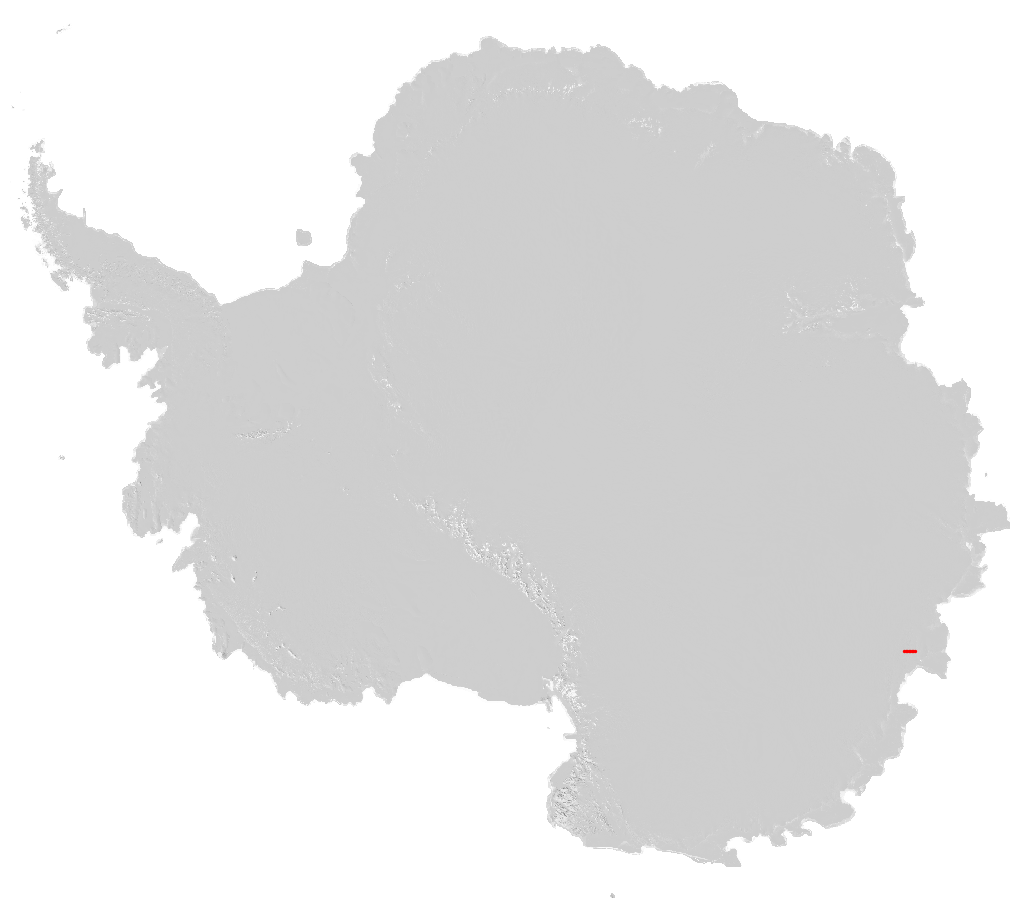

In [23]:
moa = xr.open_dataset("/Users/kim.bente/DATA/MODIS/moa750_2014_hp1_v01.nc")["moa"][::4, ::4]
moa = moa.where(moa != 0)

subset = metas[metas["granule_id"] == "ER2HI1B_2017024_TOT_JKB2r_Y27a_000"]

# Define lims
xlim = (-2.6e6, 2.8e6)
ylim = (-2.4e6, 2.4e6)
aspect = (ylim[1] - ylim[0]) / (xlim[1] - xlim[0])

fig = plt.figure(figsize = (10, 10 * aspect))
ax = fig.add_axes([0, 0, 1, 1])
ax.set_axis_off()
ax.pcolormesh(moa.x, moa.y, moa, cmap = "gray_r", rasterized = True, vmin = 500, vmax = 80000)
sc = ax.scatter(subset['X'], subset['Y'], s = 2.0, c = "red", alpha = 0.99)

ax.set_ylim(ylim)
ax.set_xlim(xlim)
ax.set_aspect('equal', adjustable = 'box')

fig.savefig("figures/radar_line.png", dpi = 300, pad_inches = 0, transparent = True)
fig.show()

# Show Bedmap3 coverage

In [30]:
bedmap123 = pd.read_csv("/Users/kim.bente/DATA/bedmap_raw_data/bedmap123.csv")

/var/folders/pv/_mchxpdj3tz_s_9735cr69pr0000gp/T/ipykernel_85222/3692276529.py:1: DtypeWarning: Columns (0: trajectory_id) have mixed types. Specify dtype option on import or set low_memory=False.
  bedmap123 = pd.read_csv("/Users/kim.bente/DATA/bedmap_raw_data/bedmap123.csv")


In [43]:
bedmap123.shape
bedmap123_subset = bedmap123[::30]

/var/folders/pv/_mchxpdj3tz_s_9735cr69pr0000gp/T/ipykernel_85222/10786169.py:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


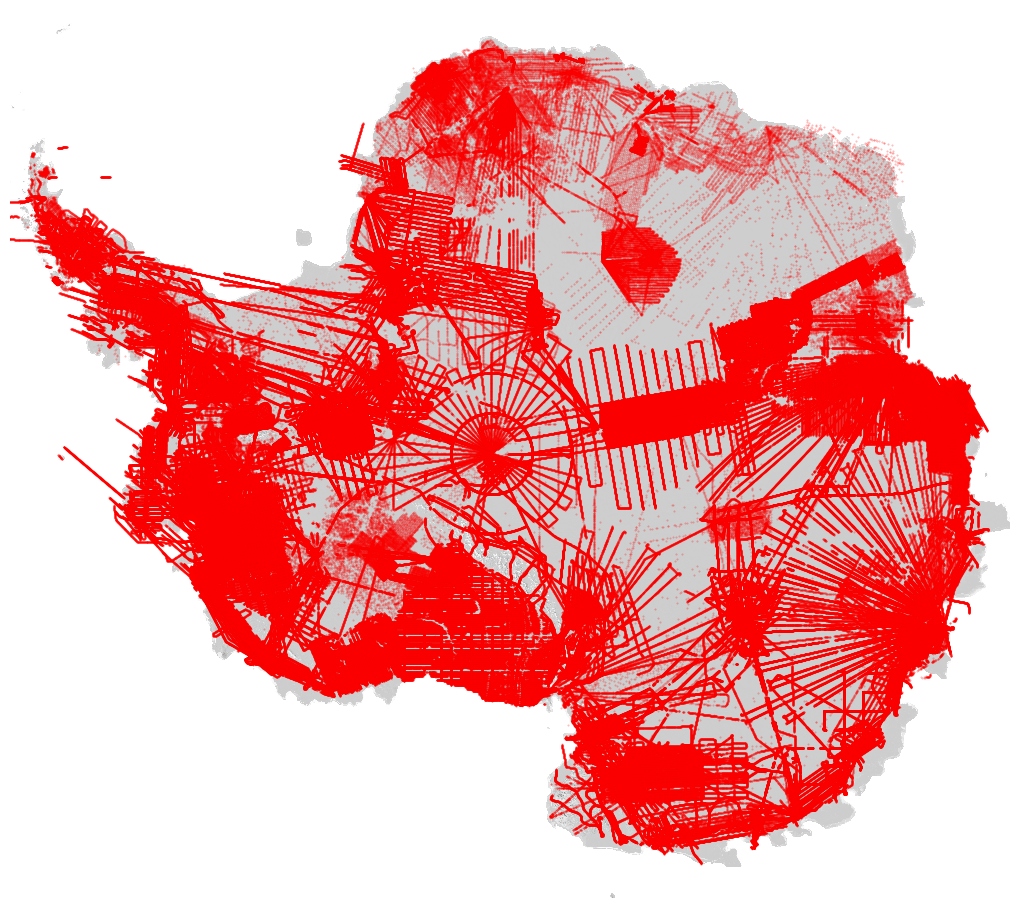

In [44]:
# Define lims
xlim = (-2.6e6, 2.8e6)
ylim = (-2.4e6, 2.4e6)
aspect = (ylim[1] - ylim[0]) / (xlim[1] - xlim[0])

fig = plt.figure(figsize = (10, 10 * aspect))
ax = fig.add_axes([0, 0, 1, 1])
ax.set_axis_off()
ax.pcolormesh(moa.x, moa.y, moa, cmap = "gray_r", rasterized = True, vmin = 500, vmax = 80000)
sc = ax.scatter(bedmap123_subset['x'], bedmap123_subset['y'], s = 0.2, c = "red", alpha = 0.3)

ax.set_ylim(ylim)
ax.set_xlim(xlim)
ax.set_aspect('equal', adjustable = 'box')

fig.savefig("figures/radar_bedmap3_extent.png", dpi = 300, pad_inches = 0, transparent = True)
fig.show()